# HELYS – Network attack classification (Random Forest, CIC-IDS2017)

Prototype of the AI layer of HELYS: classify network flows into attack categories to help prioritise SOC alerts.
Dataset: CIC-IDS2017 (Canadian Institute for Cybersecurity), not included in this repository.


In [5]:
import pandas as pd
import os

path = "data/MachineLearningCVE"  # CIC-IDS2017 CSV files (not included, see README)

files = [f for f in os.listdir(path) 
         if f.endswith('.csv') and "WorkingHours" in f]

df_list = []

for file in files:
    print("Loading:", file)
    full_path = os.path.join(path, file)
    temp_df = pd.read_csv(full_path, encoding='latin1')
    df_list.append(temp_df)

df = pd.concat(df_list, ignore_index=True)


Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv


In [7]:
df.columns = df.columns.str.strip()

In [8]:
print(df.columns)

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

In [9]:
print(df.shape)
print(df['Label'].value_counts())

(2138040, 79)
Label
BENIGN                          1833066
PortScan                         158930
DDoS                             128027
FTP-Patator                        7938
SSH-Patator                        5897
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Name: count, dtype: int64


In [10]:
df = df.drop(columns=['Flow Bytes/s', 'Flow Packets/s'], errors='ignore')

In [11]:
import numpy as np
df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [13]:
df.dropna(inplace=True)

In [12]:
df.drop_duplicates(inplace=True)

In [14]:
df.to_csv("final_cicids_combined.csv", index=False)

In [15]:
print(df.shape)

(1931587, 77)


In [16]:
df = df.sample(300000, random_state=42)

In [17]:
print(df['Label'].value_counts())

Label
BENIGN                          264175
DDoS                             19678
PortScan                         14104
FTP-Patator                        896
SSH-Patator                        485
Bot                                314
Web Attack ï¿½ Brute Force         242
Web Attack ï¿½ XSS                 101
Infiltration                         4
Web Attack ï¿½ Sql Injection         1
Name: count, dtype: int64


In [18]:
df_benign = df[df['Label'] == 'BENIGN'].sample(100000)
df_attack = df[df['Label'] != 'BENIGN']

df = pd.concat([df_benign, df_attack])

In [19]:
df = df.sample(frac=1, random_state=42)

In [20]:
print(df.shape)
print(df['Label'].value_counts())

(135825, 77)
Label
BENIGN                          100000
DDoS                             19678
PortScan                         14104
FTP-Patator                        896
SSH-Patator                        485
Bot                                314
Web Attack ï¿½ Brute Force         242
Web Attack ï¿½ XSS                 101
Infiltration                         4
Web Attack ï¿½ Sql Injection         1
Name: count, dtype: int64


In [21]:
df.to_csv("final_cicids_balanced.csv", index=False)

In [22]:
X = df.drop('Label', axis=1)
y = df['Label']

In [23]:
y = y.astype('category').cat.codes

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [27]:
from sklearn.metrics import classification_report

y_pred = rf_model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19940
           1       0.98      0.75      0.85        67
           2       1.00      1.00      1.00      4016
           3       1.00      0.99      0.99       192
           4       0.00      0.00      0.00         1
           5       0.99      1.00      1.00      2769
           6       1.00      0.97      0.99       105
           7       0.81      0.87      0.84        55
           9       0.58      0.35      0.44        20

    accuracy                           1.00     27165
   macro avg       0.82      0.77      0.79     27165
weighted avg       1.00      1.00      1.00     27165



In [28]:
# Check original class counts first
print(df['Label'].value_counts())


Label
BENIGN                          100000
DDoS                             19678
PortScan                         14104
FTP-Patator                        896
SSH-Patator                        485
Bot                                314
Web Attack ï¿½ Brute Force         242
Web Attack ï¿½ XSS                 101
Infiltration                         4
Web Attack ï¿½ Sql Injection         1
Name: count, dtype: int64


In [29]:
benign = df[df['Label'] == 'BENIGN'].sample(n=100000, random_state=42)

ddos = df[df['Label'] == 'DDoS'].sample(n=min(50000, len(df[df['Label'] == 'DDoS'])), random_state=42)
portscan = df[df['Label'] == 'PortScan'].sample(n=min(50000, len(df[df['Label'] == 'PortScan'])), random_state=42)
ftp = df[df['Label'] == 'FTP-Patator']
ssh = df[df['Label'] == 'SSH-Patator']
bot = df[df['Label'] == 'Bot']
bruteforce = df[df['Label'] == 'Web Attack ï¿½ Brute Force']
xss = df[df['Label'] == 'Web Attack ï¿½ XSS']
infiltration = df[df['Label'] == 'Infiltration']
sqli = df[df['Label'] == 'Web Attack ï¿½ Sql Injection']

df_balanced = pd.concat([
    benign, ddos, portscan, ftp, ssh, bot,
    bruteforce, xss, infiltration, sqli
])

df_balanced = df_balanced.sample(frac=1, random_state=42)
print(df_balanced['Label'].value_counts())
print(df_balanced.shape)

Label
BENIGN                          100000
DDoS                             19678
PortScan                         14104
FTP-Patator                        896
SSH-Patator                        485
Bot                                314
Web Attack ï¿½ Brute Force         242
Web Attack ï¿½ XSS                 101
Infiltration                         4
Web Attack ï¿½ Sql Injection         1
Name: count, dtype: int64
(135825, 77)


In [34]:
def map_attack(label):
    if label == "BENIGN":
        return "BENIGN"
    elif label == "DDoS":
        return "DDoS"
    elif label == "PortScan":
        return "Reconnaissance"
    elif label in ["FTP-Patator", "SSH-Patator"]:
        return "Brute Force"
    elif "Web Attack" in label:
        return "Web Attack"
    elif label in ["Bot", "Infiltration"]:
        return "Malware"
    else:
        return "Other"

df_grouped = df_balanced.copy()
df_grouped["Label"] = df_grouped["Label"].apply(map_attack)

print(df_grouped["Label"].value_counts())
print(df_grouped.shape)

Label
BENIGN        100000
DDoS           19678
Other          15803
Web Attack       344
Name: count, dtype: int64
(135825, 77)


In [35]:
df_grouped.to_csv("final_cicids_grouped.csv", index=False)

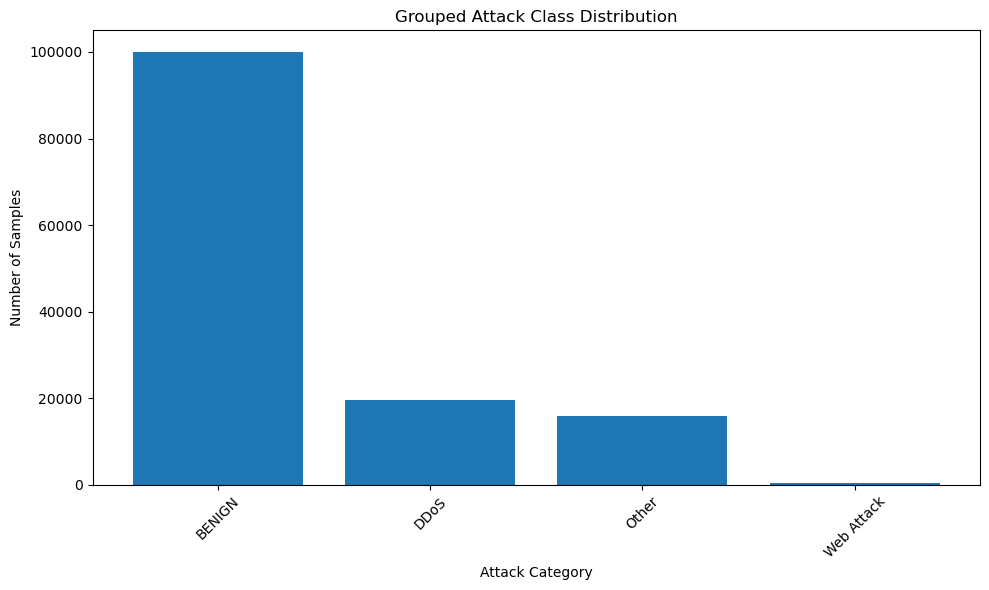

In [36]:
import matplotlib.pyplot as plt

label_counts = df_grouped["Label"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(label_counts.index, label_counts.values)
plt.xticks(rotation=45)
plt.title("Grouped Attack Class Distribution")
plt.xlabel("Attack Category")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

In [37]:
X = df_grouped.drop("Label", axis=1)
y = df_grouped["Label"]

In [38]:
y = y.astype("category")
class_names = list(y.cat.categories)
y = y.cat.codes

print(class_names)

['BENIGN', 'DDoS', 'Other', 'Web Attack']


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [42]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = rf_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

Accuracy: 0.9979753359101785
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     20000
        DDoS       1.00      1.00      1.00      3936
       Other       1.00      0.99      0.99      3160
  Web Attack       0.96      1.00      0.98        69

    accuracy                           1.00     27165
   macro avg       0.99      1.00      0.99     27165
weighted avg       1.00      1.00      1.00     27165



<Figure size 800x800 with 0 Axes>

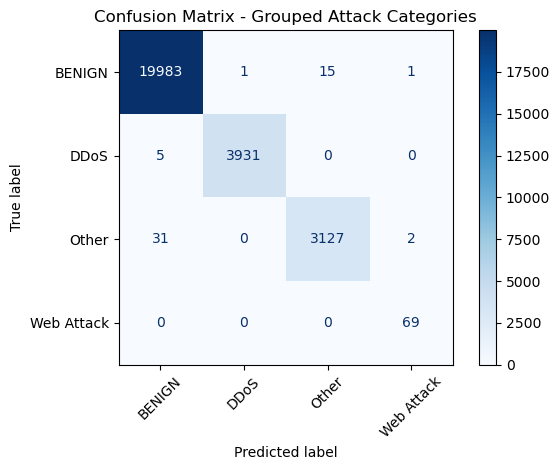

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Grouped Attack Categories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

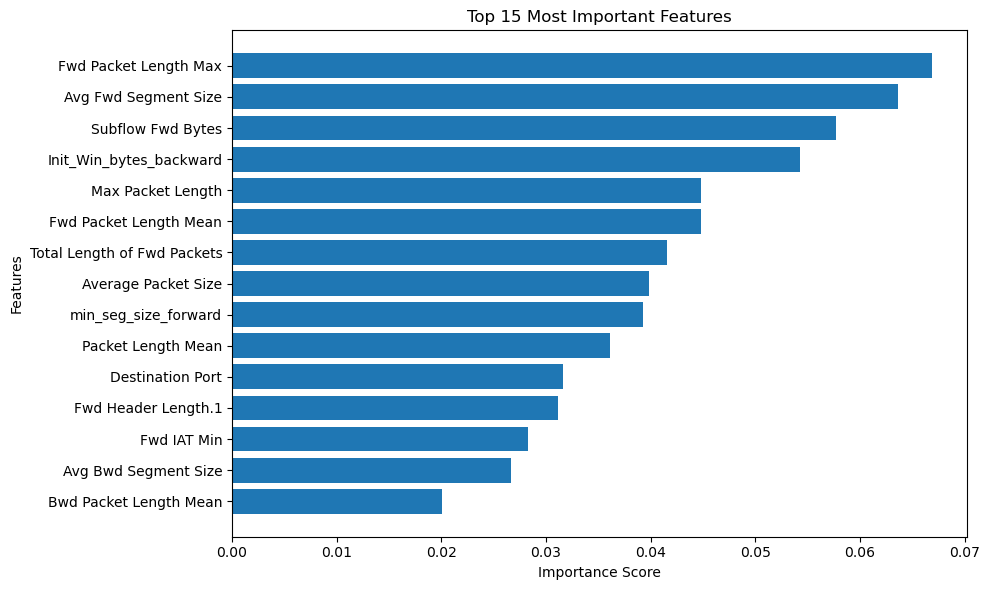

In [44]:
import pandas as pd

feature_importance = pd.Series(rf_model.feature_importances_, index=X.columns)
top_features = feature_importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_features.index[::-1], top_features.values[::-1])
plt.title("Top 15 Most Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

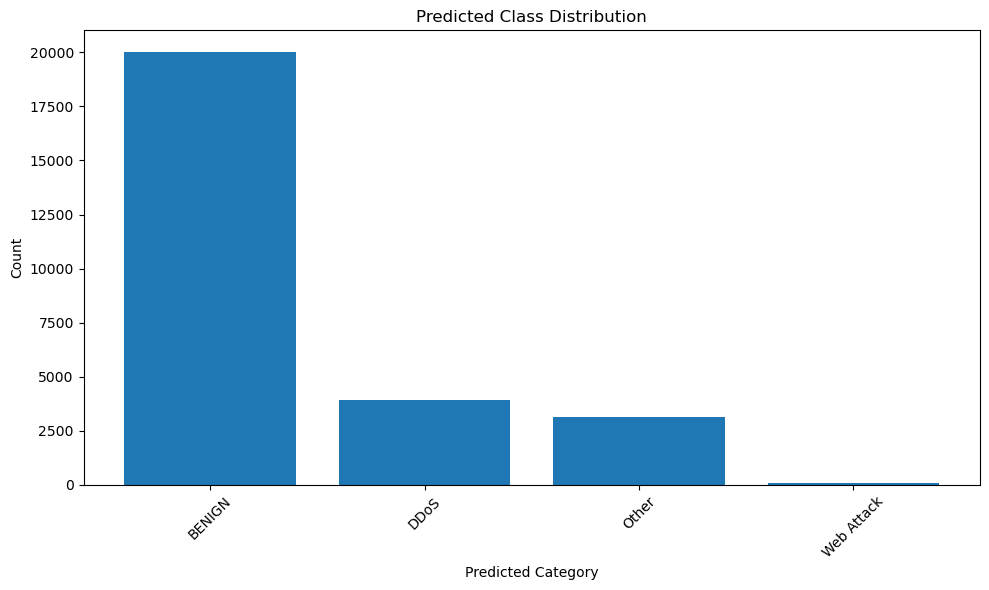

In [45]:
pred_counts = pd.Series([class_names[i] for i in y_pred]).value_counts()

plt.figure(figsize=(10, 6))
plt.bar(pred_counts.index, pred_counts.values)
plt.xticks(rotation=45)
plt.title("Predicted Class Distribution")
plt.xlabel("Predicted Category")
plt.ylabel("Count")
plt.tight_layout()
plt.show()